# Modelagem hemodinâmica 0D com svZeroDSolver: bifurcação e estenose
**Curso SimulaHub – CFD e Modelagem Hemodinâmica**

Este notebook usa o **svZeroDSolver**, o solver de ordem reduzida (0D) do projeto SimVascular. Cada vaso é representado por um circuito equivalente: resistência de Poiseuille $R$, complacência $C$, inertância $L$ e, opcionalmente, um termo não linear de estenose $S$:

$$P_{in}-P_{out} = (R + S|Q|)\,Q + L\,\dot Q$$

Todas as grandezas estão em **unidades cgs**: pressão em dyn/cm², fluxo em mL/s (cm³/s), comprimento em cm. Para converter pressão: 1 mmHg = 1333,22 dyn/cm².

## 1. Instalação

In [1]:
!pip install -q svzerod


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


## 2. Funções auxiliares
Parâmetros de vaso a partir da geometria (raio $r$, comprimento $\ell$) e das propriedades do sangue e da parede:

* $R = \dfrac{8\mu\ell}{\pi r^4}$, $\quad L = \dfrac{\rho\ell}{\pi r^2}$, $\quad C = \dfrac{3\pi r^3\ell}{2Eh}$
* Estenose (Young & Tsai): $S = K_t\dfrac{\rho}{2A_0^2}\left(\dfrac{A_0}{A_s}-1\right)^2$, com $K_t \approx 1{,}52$

In [2]:
import numpy as np, matplotlib.pyplot as plt, svzerod

MMHG = 1333.22                 # dyn/cm^2 por mmHg
MU, RHO = 0.04, 1.06           # viscosidade [P], densidade [g/cm^3]
E_H = 4.0e6 * 0.1              # módulo de Young [dyn/cm^2] x espessura [cm]

def vaso(r, ell, reducao_area=0.0, Kt=1.52):
    """Parâmetros 0D de um vaso cilíndrico; reducao_area em fração (0.7 = 70%)."""
    p = {"R_poiseuille": 8*MU*ell/(np.pi*r**4),
         "L": RHO*ell/(np.pi*r**2),
         "C": 3*np.pi*r**3*ell/(2*E_H)}
    if reducao_area > 0:
        A0 = np.pi*r**2; As = A0*(1 - reducao_area)
        p["stenosis_coefficient"] = Kt*RHO/(2*A0**2)*(A0/As - 1)**2
    return p

def onda_fluxo(Q_medio, T=1.0, t_sis=0.35, n=201, frac_diast=0.05):
    """Forma de onda pulsátil: meio seno na sístole + fluxo diastólico pequeno, escalada para Q_medio."""
    t = np.linspace(0, T, n)
    forma = np.where(t < t_sis, np.sin(np.pi*t/t_sis), 0.0) + frac_diast
    trap = getattr(np, "trapezoid", None) or np.trapz   # compatível com NumPy 1.x e 2.x
    Q = forma * Q_medio / trap(forma, t) * T
    Q[-1] = Q[0]
    return t, Q

def ultimo_ciclo(res, T=1.0):
    return res[res.time >= res.time.max() - T + 1e-9]

## 3. Bifurcação: aorta abdominal → artérias ilíacas
Uma aorta (vaso 0) se divide em duas ilíacas (vasos 1 e 2) por uma junção (`NORMAL_JUNCTION`, que impõe conservação de massa e continuidade de pressão). Cada saída recebe um Windkessel RCR, que representa o leito vascular a jusante.

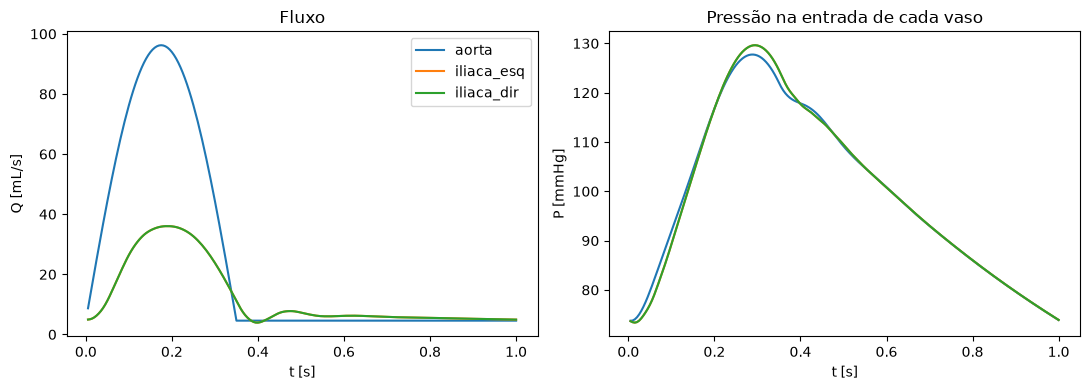

aorta        Q médio = 25.00 mL/s   P = 127.7/ 73.8 mmHg
iliaca_esq   Q médio = 12.50 mL/s   P = 129.6/ 73.4 mmHg
iliaca_dir   Q médio = 12.50 mL/s   P = 129.6/ 73.4 mmHg


In [3]:
T = 1.0
t, Q = onda_fluxo(Q_medio=25.0, T=T)           # ~1,5 L/min na aorta infrarrenal

def rcr(Rtot, tau=0.6, frac_prox=0.06):
    """RCR com resistência total Rtot, constante de tempo tau = Rd*C."""
    Rp, Rd = frac_prox*Rtot, (1-frac_prox)*Rtot
    return {"Rp": Rp, "Rd": Rd, "C": tau/Rd, "Pd": 0.0}

def modelo_bifurcacao(estenose_esq=0.0, R_saida=(10600., 10600.)):
    return {
      "simulation_parameters": {"number_of_cardiac_cycles": 10,
                                "number_of_time_pts_per_cardiac_cycle": 201},
      "boundary_conditions": [
        {"bc_name": "INFLOW", "bc_type": "FLOW", "bc_values": {"t": t.tolist(), "Q": Q.tolist()}},
        {"bc_name": "OUT_ESQ", "bc_type": "RCR", "bc_values": rcr(R_saida[0])},
        {"bc_name": "OUT_DIR", "bc_type": "RCR", "bc_values": rcr(R_saida[1])}],
      "vessels": [
        {"vessel_id": 0, "vessel_name": "aorta", "vessel_length": 12.0,
         "zero_d_element_type": "BloodVessel", "zero_d_element_values": vaso(0.8, 12.0),
         "boundary_conditions": {"inlet": "INFLOW"}},
        {"vessel_id": 1, "vessel_name": "iliaca_esq", "vessel_length": 6.0,
         "zero_d_element_type": "BloodVessel",
         "zero_d_element_values": vaso(0.4, 6.0, reducao_area=estenose_esq),
         "boundary_conditions": {"outlet": "OUT_ESQ"}},
        {"vessel_id": 2, "vessel_name": "iliaca_dir", "vessel_length": 6.0,
         "zero_d_element_type": "BloodVessel", "zero_d_element_values": vaso(0.4, 6.0),
         "boundary_conditions": {"outlet": "OUT_DIR"}}],
      "junctions": [{"junction_name": "J0", "junction_type": "NORMAL_JUNCTION",
                     "inlet_vessels": [0], "outlet_vessels": [1, 2]}]
    }

res = ultimo_ciclo(svzerod.simulate(modelo_bifurcacao()), T)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for nome in ["aorta", "iliaca_esq", "iliaca_dir"]:
    d = res[res.name == nome]
    ax[0].plot(d.time, d.flow_in, label=nome)
    ax[1].plot(d.time, d.pressure_in/MMHG, label=nome)
ax[0].set(xlabel="t [s]", ylabel="Q [mL/s]", title="Fluxo")
ax[1].set(xlabel="t [s]", ylabel="P [mmHg]", title="Pressão na entrada de cada vaso")
ax[0].legend(); plt.tight_layout(); plt.show()

for nome in ["aorta", "iliaca_esq", "iliaca_dir"]:
    d = res[res.name == nome]
    print(f"{nome:11s}  Q médio = {d.flow_in.mean():5.2f} mL/s   "
          f"P = {d.pressure_in.max()/MMHG:5.1f}/{d.pressure_in.min()/MMHG:5.1f} mmHg")

Com ramos simétricos, o fluxo se divide igualmente. **Teste:** mude `R_saida=(8000., 13000.)` e observe a redistribuição de fluxo entre as ilíacas.

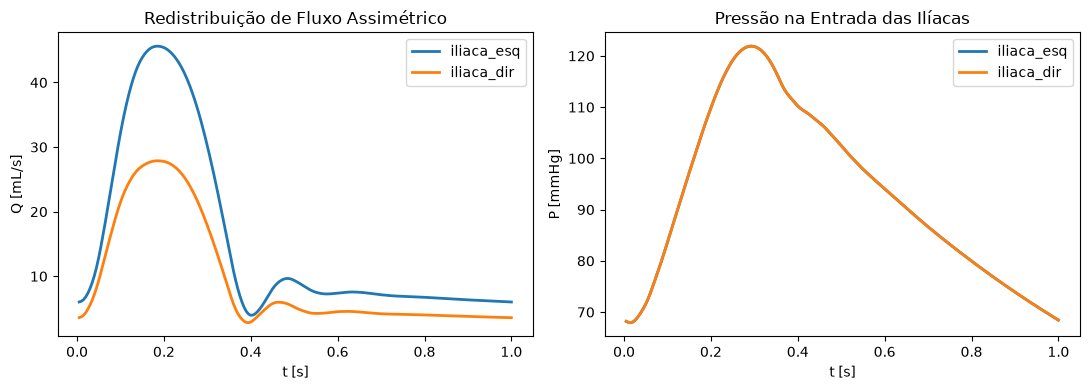

Comparação de Fluxo Médio com Saídas Assimétricas:
aorta      : Q médio = 25.00 mL/s  (100.0% do fluxo aórtico)
iliaca_esq : Q médio = 15.47 mL/s  ( 61.9% do fluxo aórtico)
iliaca_dir : Q médio =  9.53 mL/s  ( 38.1% do fluxo aórtico)


In [4]:
# Teste de saídas assimétricas: R_saida = (8000.0, 13000.0)
# A ilíaca esquerda deságua em um leito com menor resistência (vasodilatado/menor),
# enquanto a direita enfrenta maior resistência.
res_assim = ultimo_ciclo(svzerod.simulate(modelo_bifurcacao(R_saida=(8000., 13000.))), T)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for nome, cor in zip(["iliaca_esq", "iliaca_dir"], ["tab:blue", "tab:orange"]):
    d = res_assim[res_assim.name == nome]
    ax[0].plot(d.time, d.flow_in, label=nome, color=cor, lw=2)
    ax[1].plot(d.time, d.pressure_in/MMHG, label=nome, color=cor, lw=2)
ax[0].set(xlabel="t [s]", ylabel="Q [mL/s]", title="Redistribuição de Fluxo Assimétrico")
ax[1].set(xlabel="t [s]", ylabel="P [mmHg]", title="Pressão na Entrada das Ilíacas")
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

print("Comparação de Fluxo Médio com Saídas Assimétricas:")
for nome in ["aorta", "iliaca_esq", "iliaca_dir"]:
    d = res_assim[res_assim.name == nome]
    print(f"{nome:11s}: Q médio = {d.flow_in.mean():5.2f} mL/s  ({d.flow_in.mean()/25.0*100:5.1f}% do fluxo aórtico)")


## 4. Estenose na ilíaca esquerda
Agora inserimos uma estenose na ilíaca esquerda e variamos o grau de redução de área. Como índice de gravidade usamos a razão de pressões médias através da lesão, $P_d/P_a$ (análoga ao FFR usado em coronárias, em que valores abaixo de ~0,80 indicam lesão hemodinamicamente significativa).

 redução   S [cgs]   Q_esq   Q_dir   ΔP_méd  Pd/Pa
      0%       0.0   12.50   12.50     0.2    1.00
     50%       3.2   12.46   12.54     0.9    0.99
     70%      17.4   12.30   12.70     3.4    0.97
     80%      51.0   12.00   13.00     8.2    0.92


     90%     258.3   10.85   14.15    26.5    0.76


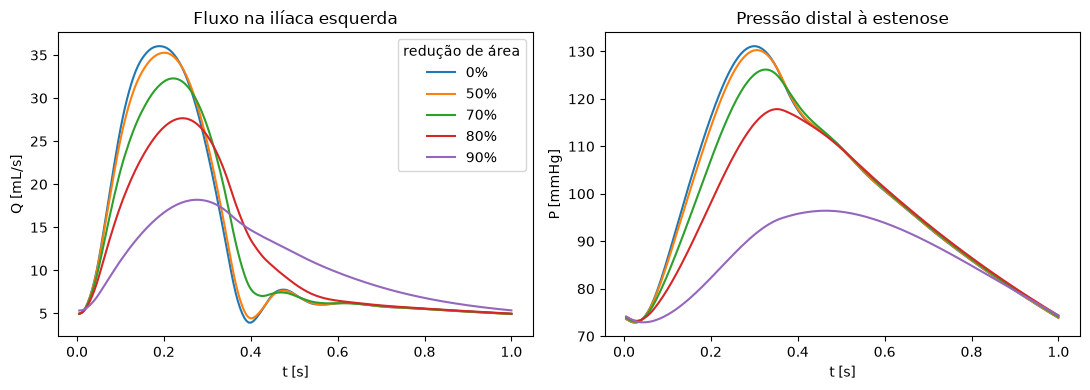

In [5]:
graus = [0.0, 0.5, 0.7, 0.8, 0.9]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
print(f"{'redução':>8s} {'S [cgs]':>9s} {'Q_esq':>7s} {'Q_dir':>7s} {'ΔP_méd':>8s} {'Pd/Pa':>6s}")
for g in graus:
    r = ultimo_ciclo(svzerod.simulate(modelo_bifurcacao(estenose_esq=g)), T)
    e, dr = r[r.name == "iliaca_esq"], r[r.name == "iliaca_dir"]
    Pa, Pd = e.pressure_in.mean(), e.pressure_out.mean()
    S = vaso(0.4, 6.0, g).get("stenosis_coefficient", 0.0)
    print(f"{g*100:7.0f}% {S:9.1f} {e.flow_in.mean():7.2f} {dr.flow_in.mean():7.2f} "
          f"{(Pa-Pd)/MMHG:7.1f}  {Pd/Pa:6.2f}")
    ax[0].plot(e.time, e.flow_in, label=f"{g*100:.0f}%")
    ax[1].plot(e.time, e.pressure_out/MMHG, label=f"{g*100:.0f}%")
ax[0].set(xlabel="t [s]", ylabel="Q [mL/s]", title="Fluxo na ilíaca esquerda")
ax[1].set(xlabel="t [s]", ylabel="P [mmHg]", title="Pressão distal à estenose")
ax[0].legend(title="redução de área"); plt.tight_layout(); plt.show()

### O que observar
* O termo $S|Q|Q$ é **quadrático** no fluxo: a queda de pressão cresce lentamente até ~70% de redução e depois dispara. Isso reproduz o conceito clínico de **estenose crítica**.
* O fluxo **se redistribui** para a ilíaca direita, que passa a receber mais sangue.
* A pressão distal perde amplitude sistólica, pois a estenose atua como um filtro não linear.

## 5. Exercícios
1. Varie a rigidez da parede (`E_H`) e observe a pressão de pulso na aorta. Qual a relação com o envelhecimento arterial?
2. Simule **vasodilatação** (exercício físico) na perna estenótica: reduza a resistência de saída esquerda pela metade. O que acontece com $P_d/P_a$? Por que o FFR clínico é medido sob hiperemia?
3. Coloque estenoses de 70% nos **dois** ramos e compare com o caso unilateral.
4. Altere $K_t$ (coeficiente empírico de expansão) entre 1,0 e 2,0 e discuta a sensibilidade do modelo a esse parâmetro.